# Projection changes between using one or more reanalyses
- Mortality: comparing to just using GMFD (i.e., Carleton et al.)
- GDP pc: comparing to UDel damage function fit using mean of BCD-ME reanalyses
- payroll: comparing to PRISM damage function fit using mean of BCD-ME reanalyses

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm
from scipy import stats as sstats
import copy

import matplotlib as mpl
from matplotlib import pyplot as plt

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp,nan_argmax_xr
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll

dir_list = get_params()





In [2]:
imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
                      'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
                      'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}
        

In [3]:
# Load impacts projections

dists = {}
for proc in ['mortality','gdppc','payroll']:
    #--------------------------
    # Load --------------------
    #--------------------------
    if proc == 'mortality':
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*ALLGWL*.zarr'))
    else:
        # Get crossfits
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}-crossfit_agg_*ALLGWL*.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        if 'idv' in ds_tmp.coords:
            ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dss = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')
    
    if proc == 'mortality':
        dss = dss.sel(imp_params[proc])
    dss = dss.sel(gwl=[0.61,2])
    dss = dss.reset_index('idv').set_index(idv = ['model','exprun']).drop_vars(['experiment','run'])
    dss = dss.set_index(poly_idx='locid').rename({'poly_idx':'locid'})
    
    # Figure out how many BCD-ME members reach a given GWL
    # (copy.deepcopy() necessary as a workaround around a numpy bug
    # affecting the unstack a few lines down that's triggered 
    # indirectly by the reset_index here)
    gwl_counter = copy.deepcopy(dss.maxgwl).load().reset_index('idv').groupby(['model','maxgwl']).count()
    gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
    
    #---------------------------
    # Get the balanced panel from 
    # the main text figures
    #---------------------------
    max_gwl = 3
    if proc == 'payroll':
        nruns = 10
    else:
        nruns = 13
    
    gwlmods = gwl_counter.sel(maxgwl=3)
    proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
    
    dss_tmp = dss.isel(idv = dss.maxgwl.load()>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
    dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
    dss_tmp = dss_tmp.unstack('idv')['d'+proc]
    dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
    
    #---------------------------
    # Calc changes
    #---------------------------
    ddss_tmp = dss_tmp.sel(gwl=2) - dss_tmp.sel(gwl=0.61)
    ddss_tmp2 = ddss_tmp.stack(idv = ['model','exprun']).dropna('idv',how='all').load()

    #---------------------------
    # Calc aggregated changes
    #---------------------------
    # Get weights (population or dividends)
    if proc == 'mortality':
        allpreds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
        pop = allpreds.pop.sel(ageset='agetotal',pred_ssp='ssp3',pred_model='high',gwl=0.61).mean('year').compute()
        pop = pop.rename({'hierid':'locid'}) 
    elif proc == 'gdppc':
        pop = load_shp('gdppc').loc[:,('locid','POP_CNTRY')]
        pop = pop.set_index('locid').to_xarray().POP_CNTRY
    elif proc == 'payroll':
        pop = pd.read_csv(dir_list['aux']+'hle_replication_data.csv').groupby('fips')['Dividends'].mean()
        pop = pop.to_xarray().rename({'fips':'locid'})
        pop['locid'] = [str(fips).zfill(5) for fips in pop.locid.values]
    # Get aggregated values 
    dists[proc] = ((ddss_tmp2*pop).sum('locid')/pop.sum('locid'))

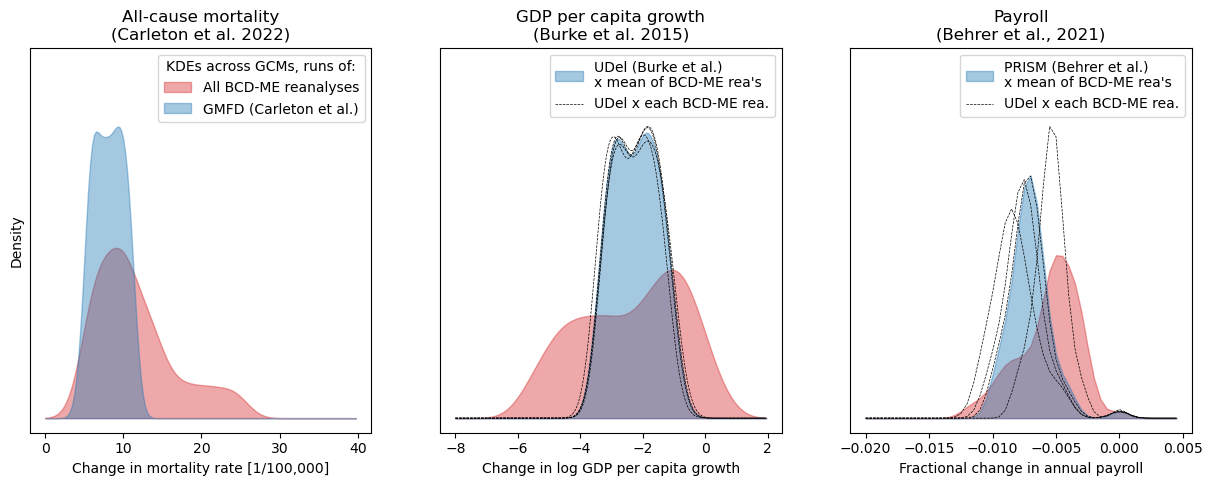

In [4]:
add_rea_guides = True

test_locs = {'mortality':np.arange(0,40,0.25),
             'gdppc':np.arange(-8,2,0.05),
             'payroll':np.arange(-0.02,0.005,0.0005)}

labels = {'mortality':{'all':'All BCD-ME reanalyses',
                       'ref':'GMFD (Carleton et al.)'},
          'gdppc':{'all':'All BCD-ME reanalyses',
                   'ref':"UDel (Burke et al.)\nx mean of BCD-ME rea's"},
          'payroll':{'all':'All BCD-ME reanalyses',
                     'ref':"PRISM (Behrer et al.)\nx mean of BCD-ME rea's"}}

xlabels = {'mortality':'Change in mortality rate [1/100,000]',
           'gdppc':'Change in log GDP per capita growth',
           'payroll':'Fractional change in annual payroll'}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}


fig = plt.figure(figsize=(15,5))

for plt_idx,proc in enumerate(dists):
    ax = plt.subplot(1,len(dists),plt_idx+1)

    # Make KDEs of distributions
    kde = {'all':sstats.gaussian_kde(dists[proc].values.flatten())}
    if proc == 'mortality':
        kde = {'all':sstats.gaussian_kde(dists[proc].values.flatten())}
        kde['ref'] = sstats.gaussian_kde(dists[proc].sel(proj_base='GMFD').values.flatten())
    else:
        # Recover just the matching fit and projected reanalyses
        dist_tmp = dists[proc].where(dists[proc].fit_mod == dists[proc].proj_base).stack(mods = ['fit_mod','proj_base']).dropna('mods',how='all')
        kde = {'all':sstats.gaussian_kde(dist_tmp.values.flatten())}
        if proc == 'gdppc':
            kde['ref'] = sstats.gaussian_kde(dists[proc].sel(fit_mod='UDel').mean('proj_base').values.flatten())
        elif proc == 'payroll':
            kde['ref'] = sstats.gaussian_kde(dists[proc].sel(fit_mod='PRISM').mean('proj_base').values.flatten())
    kdet = {typ:k(test_locs[proc]) for typ,k in kde.items()}
    kdet = {typ:k/k.sum() for typ,k in kdet.items()}


    # Plot
    h0 = ax.fill_between(test_locs[proc],kdet['all'],color='tab:red',alpha=0.4,label=labels[proc]['all'])
    h1 = ax.fill_between(test_locs[proc],kdet['ref'],color='tab:blue',alpha=0.4,label=labels[proc]['ref'])

    # Show UDel / PRISM vs. each of the individual bias-corrected and downscaled prods
    if add_rea_guides and proc != 'mortality':
        for proj_base in dists[proc].proj_base.values:
            kde_tmp = sstats.gaussian_kde(dists[proc].sel(fit_mod=('PRISM' if proc == 'payroll' else 'UDel'),proj_base=proj_base).values.flatten())
            kde_tmp = kde_tmp(test_locs[proc])
            kde_tmp = kde_tmp/kde_tmp.sum()
            h2 = ax.plot(test_locs[proc],kde_tmp,linewidth=0.5,linestyle='--',color='k',label='UDel x each BCD-ME rea.')
            h2 = h2[0]
    # Annotations
    ax.set_title(proc_full_names[proc])
    ax.set_xlabel(xlabels[proc])
    ax.set_ylim(ax.get_ylim()[0],ax.get_ylim()[1]+0.2*(ax.get_ylim()[1]-ax.get_ylim()[0]))
    if plt_idx == 0:
        ax.legend(title='KDEs across GCMs and runs, with:')
    else:
        if add_rea_guides:
            ax.legend([h1,h2],
                      [h1.get_label(),h2.get_label()])
        else:
            ax.legend([h1],[h1.get_label()])
    ax.set_yticks([])

    if plt_idx == 0:
        ax.set_ylabel('Normalized density')

